# STATS 201 · Week 5 · Research and Innovation

## Match the method to the question

Start with the two-page methods cheat sheet from Ed Discussion. Choose a question you care about, decide what each row records, and match your method to the evidence the question needs. This tutorial follows the five active exercises in the Week 5 Ed Discussion kit and Methods Lab.

| Exercise | What you will do |
|---|---|
| Data and measurement | Turn one ad title and its duration into numbers a model can use. |
| Explanation | Group ads by recorded messages and interpret each group. |
| Prediction | Predict the human Environment label for an unseen ad. |
| Causal inference | Compare growth in followers before and after a Bluesky account first appears in a starter pack. |
| Comparative evaluation and revision | Compare three models on the same test ads, then decide what to test next. |
| Optimization | **TBD.** See the methods cheat sheet for the overview. |

### Use the lab

1. [Open in Google Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/08-innovation/week05_matching_ml_methods.ipynb). Choose **File → Save a copy in Drive** if you want to keep your edits.
2. Read the saved examples or run the notebook from the top with a standard CPU runtime. The first cell installs the packages. The data cell needs an internet connection to read the public ads.
3. Read the question and make a prediction. Change an option in the exercise cell and run that cell again. In Jupyter, edit the value beside the `# @param` comment. Results appear directly below the code.
4. Carry one observation and one revision into the **Team project design** at the end. Use Ed for the class discussion.

**Before class.** Notice how a research question changes after you test an idea. [Stuart Firestein on pursuing uncertainty](https://www.youtube.com/watch?v=nq0_zGzSc8g&t=885s) · [Reshma Saujani on trying before you feel ready](https://www.youtube.com/watch?v=fC9da6eqaqg&t=351s)

In [1]:
# @title Install Python packages
%pip -q install "autogluon.tabular[lightgbm]==1.5.0" paretoset==1.2.5 "pandas==2.2.3" "scikit-learn==1.7.2" "statsmodels==0.14.5"

### The two datasets

- **Oil and gas advertising benchmark.** Morio and colleagues published 193 training ads and 193 separate test ads for the YouTube part used here. One row is one video. We use its title (text), duration (seconds), and frame labels (the messages identified by human reviewers). `Environment` is coded 1 when the label is present and 0 otherwise. The benchmark tests which messages can be identified in these public ads. Direct evidence on environmental performance would require other measurements. Read the [dataset card and reuse terms](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark) and [Section 2.2 of the paper](https://papers.nips.cc/paper_files/paper/2025/hash/7fe388e4c36b7d6a2aed2e4629804169-Abstract-Datasets_and_Benchmarks_Track.html). The source marks its annotations CC BY-NC 4.0.
- **Bluesky follower counts.** The class table contains rounded readings of two group averages on nine relative days in Balduf and colleagues’ [Figure 10(a)](https://www.eecs.qmul.ac.uk/~tysong/files/ICWSM25-Bluesky.pdf#page=8). An account is the study unit. Each row in our small table is a day on which the paper shows the average for each group. The numbers provide the class calculation. Individual account records are needed for an account-level analysis.

In [2]:
# @title Load the published ad splits
%matplotlib inline
from functools import lru_cache
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

DATA_URL = "https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark/resolve/98c8b5266ae6247f71957f7b8b4ad7919cc7262e"

@lru_cache(maxsize=2)
def ads(split):
    filename = f"yt_video.{split}.jsonl"
    local = Path(filename)
    return pd.read_json(local if local.is_file() else f"{DATA_URL}/{filename}", lines=True)


def environment(rows):
    return rows["labels"].map(lambda labels: int("Environment" in labels))


def check_vote(answer, correct, feedback):
    if answer == "Choose after reading":
        print("Choose A, B, C or D to check your reasoning.")
    else:
        print(("Correct. " if answer == correct else "Revisit your choice. ") + feedback)


train, test = ads("train"), ads("test")
print(f"Training ads: {len(train)} · Test ads: {len(test)}")
print(f"Training Environment labels: {environment(train).sum()} · Test Environment labels: {environment(test).sum()}")
display(train[["video_title", "video_length_seconds", "labels"]].head(3))

Training ads: 193 · Test ads: 193
Training Environment labels: 84 · Test Environment labels: 78


,video_title,video_length_seconds,labels
0,Zero In™ with Oxy,79,"[Economy and Business, Work, Environment, Gree..."
1,Want a Journey Like No Other? #IOCL XP95 premi...,105,"[Environment, Community and Life]"
2,"Oil - more than just fuel: ""No oil - no internet""",76,[Community and Life]


## Data and measurement

### How does an ad become a row of numbers?

Record how a reviewer labeled an ad and turn its title and duration into a row of numbers.

A frame is the angle an ad takes, such as emphasizing emissions reductions. A human annotation is a label added by a reviewer. Here Environment means the reviewer identified environmental messaging.

The training set is the group of ads used to learn the rules. The test set, also called the held-out set, contains separate ads used to check how the rules work on unseen cases. A token is a word-like piece of a title. The vocabulary is the list of known tokens from the training titles, with one numerical column per token.

Term frequency (TF) is the number of times the word occurs in this title. Document frequency (DF) is the number of training titles that contain the word at least once. Inverse document frequency (IDF) is a rarity weight based on DF. A word in one training title gets a higher IDF than a word in 50 titles. Here each title counts as one document. Term frequency–inverse document frequency (TF–IDF) multiplies the count by the rarity weight and then rescales the title’s numbers. This rescaling is called normalization. Standardizing duration means subtracting the average training duration and dividing by its standard deviation, a measure of how spread out those durations are.

**Data.** The authors provide 193 training ads and 193 separate test ads. Learn the word and duration transformations from the training ads, then apply those same transformations to each test ad.

- [Hugging Face · annotation release](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark)
- [Morio et al. · NeurIPS 2025](https://papers.nips.cc/paper_files/paper/2025/hash/7fe388e4c36b7d6a2aed2e4629804169-Abstract-Datasets_and_Benchmarks_Track.html)

| Symbol | Field or result | Meaning |
|---|---|---|
| i, Lᵢ | video_id, labels | One ad, with a list of human-assigned frames. |
| Yᵢ | Environment ∈ labels | 1 if present, 0 if absent. This is the observed label used later. |
| Xᵣₐw | video_title, video_length_seconds | A string and a number in seconds. Both are known before human coding. |
| Xᵢ | StandardScaler + TfidfVectorizer | One standardized duration and 648 numerical title columns. Each test ad reuses the training vocabulary and scale. |

**Vote before running.** Your team receives a previously unseen company report. How should it turn the report into the input row X for a fair test?

- **A.** Learn a separate vocabulary for this report
- **B.** Use the report’s future human label as a feature
- **C.** Reuse the training vocabulary, rarity weights (IDF) and duration scale
- **D.** Learn new weights from all test reports first

Select `poll_choice` in the exercise cell and rerun it to check your reasoning. The class vote is in Ed Discussion.

### Equation and pseudocode

pandas.read_json, scikit-learn CountVectorizer, TfidfVectorizer and StandardScaler

$$
Y_i=\mathbf{1}\{\mathrm{Environment}\in L_i\},\qquad \hat p=\frac{1}{n}\sum_iY_i
$$

The label indicator counts a video once. n is the number of training videos.

**1. Find the raw weight for each word.** Multiply the word's count in this title, $c_{ij}$, by its training rarity weight, $\mathrm{idf}_j$. Here $\mathrm{df}_j$ is the number of training titles that contain word $j$.

$$
\mathrm{idf}_j=1+\ln\frac{1+n}{1+\mathrm{df}_j},\qquad v_{ij}=c_{ij}\,\mathrm{idf}_j
$$

**2. Find one shared divisor for the title.** Square its raw word weights, add the squares, then take the square root. This is the length of the title's word vector, also called its L2 norm.

$$
\ell_i=\sqrt{\sum_k v_{ik}^2}
$$

**3. Divide to get the final TF–IDF weight.** Divide every raw word weight in the title by that same length. If the title has no known words, keep all word weights at zero. The duration is standardized separately.

$$
x_{ij}=\frac{v_{ij}}{\ell_i}=\frac{c_{ij}\,\mathrm{idf}_j}{\sqrt{\sum_k (c_{ik}\,\mathrm{idf}_k)^2}}\quad\text{for }\ell_i>0
$$

$$
z_i=(d_i-\bar d)/s_d,\quad s_d^2=n^{-1}\sum_i(d_i-\bar d)^2,\quad X_i=(z_i,x_{i1},\ldots,x_{i648})
$$

Duration d is measured in seconds. The mean and population standard deviation use only training durations.

1. Load the original training and test records. Set Y to 1 when the reviewer list contains Environment.
2. On training titles, learn the vocabulary and each word’s document frequency. Fit a scaler on training durations.
3. Split a held-out title into words. Count each known word, multiply by its training rarity weight, then divide each raw weight by the square root of the sum of their squares.
4. Apply the training scaler to seconds. Join the scaled duration and the 648 word weights to form X.

[pandas · read_json](https://pandas.pydata.org/docs/reference/api/pandas.read_json.html) · [scikit-learn · TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [scikit-learn · CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html) · [scikit-learn · StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [3]:
# @title Explore a title, its tokens and its numerical inputs
from math import sqrt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import StandardScaler

poll_choice = "Choose after reading" # @param ["Choose after reading", "A", "B", "C", "D"]
held_out_example = "Who we are" # @param ["Who we are", "Supporting your home team", "Road Ahead New Mexico :15", "Stuntwoman", "24 Solar Terms: Major Heat"]
show_through = "Final input row" # @param ["Raw record", "Tokens and counts", "Word rarity and weights", "Final input row"]
training_frame = "Environment" # @param ["Environment", "Green Innovation", "Work", "Economy and Business"]
custom_title = "" # @param {type:"string"}
use_custom_duration = False # @param {type:"boolean"}
custom_seconds = 110 # @param {type:"number"}

check_vote(poll_choice, 'C', 'Correct choice: Reuse the training vocabulary, rarity weights (IDF) and duration scale. The vocabulary, rarity weights (IDF) and duration scale all come from training. Reuse them on new ads.')

example_rows = {"Who we are": 1, "Supporting your home team": 0, "Road Ahead New Mexico :15": 4,
                "Stuntwoman": 5, "24 Solar Terms: Major Heat": 16}
row = test.iloc[example_rows[held_out_example]]
custom = bool(custom_title.strip())
title = custom_title.strip() if custom else row["video_title"]
seconds = custom_seconds if use_custom_duration else row["video_length_seconds"]
if not (0 <= seconds < float("inf")):
    raise ValueError("Enter a finite duration of zero seconds or more.")

frame_count = train["labels"].map(lambda labels: training_frame in labels).sum()
print(f"{training_frame} appears in {frame_count} / {len(train)} training ads ({frame_count/len(train):.1%}).")
print(f"Title: {title!r} · Duration: {seconds:g} seconds")
if custom or use_custom_duration:
    print("Edited input. The reference annotation applies to the original ad.")
else:
    print(f"Reviewer’s Environment label: {int('Environment' in row['labels'])}")

words = TfidfVectorizer().fit(train["video_title"])
scaler = StandardScaler().fit(train[["video_length_seconds"]])
counts = CountVectorizer(vocabulary=words.vocabulary_).transform([title])
weights = words.transform([title]).tocoo()
word_names = words.get_feature_names_out()
trace = pd.DataFrame([
    {"Word": word_names[j], "Count in title": int(counts[0, j]),
     "Rarity weight (IDF)": words.idf_[j], "Final TF–IDF weight": value}
    for j, value in sorted(zip(weights.col, weights.data))
], columns=["Word", "Count in title", "Rarity weight (IDF)", "Final TF–IDF weight"])

if show_through != "Raw record":
    tokens = words.build_analyzer()(title)
    print("Tokens:", tokens)
    print("Tokens outside the training vocabulary:", list(dict.fromkeys(t for t in tokens if t not in words.vocabulary_)))
    if show_through == "Tokens and counts":
        display(trace[["Word", "Count in title"]])
    else:
        raw_weights = trace["Count in title"] * trace["Rarity weight (IDF)"]
        trace.insert(3, "Count × IDF", raw_weights)
        display(trace.round(3))
        if trace.empty:
            print("No known words. The word vector stays all zeros.")
        else:
            sum_of_squares = raw_weights.pow(2).sum()
            title_length = sqrt(sum_of_squares)
            print(f"Add up the squared raw weights to get {sum_of_squares:.3f}.")
            print(f"Shared divisor for this title = √{sum_of_squares:.3f} ≈ {title_length:.3f}.")
            example = trace.iloc[0]
            print(f"Final weight for {example['Word']!r} ≈ "
                  f"{example['Count × IDF']:.3f} ÷ {title_length:.3f} ≈ "
                  f"{example['Final TF–IDF weight']:.3f}.")
if show_through == "Final input row":
    scaled = scaler.transform(pd.DataFrame({"video_length_seconds": [seconds]}))[0, 0]
    inputs = [["Duration (standardized)", scaled], *zip(trace["Word"], trace["Final TF–IDF weight"])]
    print(f"Input X has {len(word_names) + 1} columns. Unshown word columns have value 0.")
    display(pd.DataFrame(inputs, columns=["Input column", "Value"]).round(3))

Choose A, B, C or D to check your reasoning.
Environment appears in 84 / 193 training ads (43.5%).
Title: 'Who we are' · Duration: 110 seconds
Reviewer’s Environment label: 1
Tokens: ['who', 'we', 'are']
Tokens outside the training vocabulary: []
Add up the squared raw weights to get 70.630.
Shared divisor for this title = √70.630 ≈ 8.404.
Final weight for 'are' ≈ 4.882 ÷ 8.404 ≈ 0.581.
Input X has 649 columns. Unshown word columns have value 0.


,Word,Count in title,Rarity weight (IDF),Count × IDF,Final TF–IDF weight
0,are,1,4.882,4.882,0.581
1,we,1,3.965,3.965,0.472
2,who,1,5.575,5.575,0.663


,Input column,Value
0,Duration (standardized),0.483
1,are,0.581
2,we,0.472
3,who,0.663


### Read the title-to-number trace

Of the 193 training ads, 84 have the Environment label. In the title “Who we are,” each word occurs once. The raw weights for “are,” “we,” and “who” are therefore their IDFs, approximately 4.882, 3.965, and 5.575. All three final weights use the same divisor.

$$
\sqrt{4.882^2+3.965^2+5.575^2}\approx 8.40,\qquad x_{i,\text{are}}\approx\frac{4.882}{8.404}\approx 0.581
$$

The final weights for “we” and “who” are 0.472 and 0.663. Its duration of 110 seconds is 0.483 standard deviations above the training mean. Only those three words appear. The other 645 word columns are zero. A title made entirely of words outside the training vocabulary gives zero in every word column.

Switch to **Tokens and counts**, then to **Word rarity and weights**. Read the **Count × IDF** column and the division printed below the table. Try a title made from an unfamiliar invented word and read the word columns. To try a different duration, set `use_custom_duration` and enter `custom_seconds`. The observed label belongs to the original ad.

**Connect to your project.** What raw text field and outcome will you collect, which transformation will you fit on training cases, and how will you handle a new word?

For a financial disclosure, learn the vocabulary from earlier filings, transform later filings, and record how often new terms fall outside the vocabulary.

## Explanation

### Which messages appear together in energy ads?

Record which of four labels one ad has, then describe the group of ads it resembles.

A feature is a measured property of an ad. A binary feature uses two values. Here 1 means a reviewer assigned the label and 0 means they did not. A cluster is a group of similar rows. K-means is a grouping algorithm. K says how many groups to form. A cluster center is an average row for a group. A center value of 0.75 for Work means 75% of that group’s ads carry the Work label. Work refers to jobs and workers. Economy and Business refers to economic or business activity.

**Data.** 193 training videos with expert labels. One row per ad and four equally weighted 0/1 columns. An ad can score 1 on several columns.

- [Frame definitions and source ads](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark)
- [Morio et al. · Section 2.2](https://papers.nips.cc/paper_files/paper/2025/hash/7fe388e4c36b7d6a2aed2e4629804169-Abstract-Datasets_and_Benchmarks_Track.html)

| Symbol | Field or result | Meaning |
|---|---|---|
| Xᵢ₁ | Environment ∈ labels | Environmental messaging. |
| Xᵢ₂ | Green Innovation ∈ labels | Greener technology or innovation. |
| Xᵢ₃ | Work ∈ labels | Employment, workers or workforce activity. |
| Xᵢ₄ | Economy and Business ∈ labels | Business activity or economic contribution. |
| Wᵢg | fitted group membership | 1 for the group selected for ad i. No outcome Y is required. |
| Hgⱼ | cluster_centers_[g,j] | Share of group g with frame j. Each row is a typical four-feature profile. |

**Vote before running.** “Meet Hessa” has exactly the labels Work and Economy and Business. Which X row goes into k-means in the order shown above?

- **A.** [1, 0, 0, 1]
- **B.** [0, 0, 1, 1]
- **C.** [0, 1, 1, 0]
- **D.** [1, 1, 0, 0]

Select `poll_choice` in the exercise cell and rerun it to check your reasoning. The class vote is in Ed Discussion.

### Equation and pseudocode

K-means clustering · scikit-learn KMeans.fit_predict

$$
X_{ij}=\mathbf 1\{f_j\in L_i\},\quad X\approx WH,\quad \min_{W,H}\sum_{i=1}^{193}\sum_{g=1}^K W_{ig}\lVert X_i-H_g\rVert_2^2
$$

Each row of W has one 1 and K−1 zeros. Four features are equally weighted.

$$
g_i=\arg\min_g\sum_{j=1}^{4}(X_{ij}-H_{gj})^2,\quad H_{gj}=\frac{\sum_i W_{ig}X_{ij}}{\sum_i W_{ig}}
$$

Assign each ad to the nearest center. Then replace each center with the average input row for its group. KMeans uses k-means++, a way to choose initial centers spread across the data. It tries 20 starts and keeps the grouping with the smallest total squared distance to the assigned centers.

1. For each training ad, encode Environment, Green Innovation, Work, and Economy and Business in that order.
2. Choose K = 2. Ask KMeans to initialize centers, assign each row to its nearest center, and update to the mean.
3. Repeat the assignments and averages until the groups settle or the algorithm reaches its limit. Keep the best of 20 starts.
4. Read feature shares and group sizes. Change K to 3 and check which substantive profile appears.

[scikit-learn · KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

Choose A, B, C or D to check your reasoning.
Meet Hessa - the first female engineer to work at the Shah Gas Field
Reviewer labels: Economy and Business, Work
Input row: [0, 0, 1, 1] · Assigned group: 1
The frame columns give shares of ads in each group. For example, 0.75 means 75%.


,Environment,Green Innovation,Work,Economy and Business,Ads
Group,,,,,
0,1.0,0.43,0.61,0.44,84
1,0.0,0.03,0.47,0.15,109


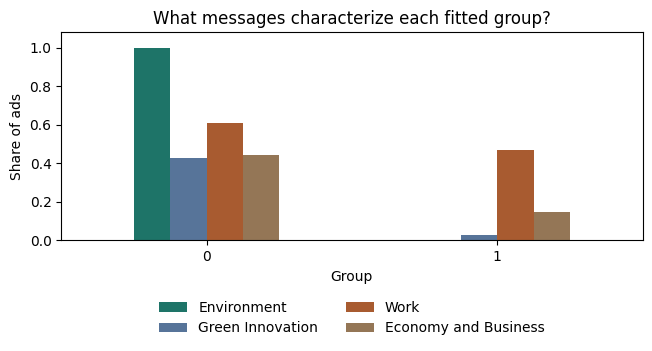

In [4]:
# @title Group the ads by four messages
from sklearn.cluster import KMeans

poll_choice = "Choose after reading" # @param ["Choose after reading", "A", "B", "C", "D"]
training_example = "Meet Hessa" # @param ["Meet Hessa", "Methane emissions", "Keechi Wind Farm", "No oil - no internet", "Zero In with Oxy"]
number_of_groups = 2 # @param [2, 3] {type:"raw"}

check_vote(poll_choice, 'B', 'Correct choice: [0, 0, 1, 1]. The feature order is Environment, Green Innovation, Work, Economy and Business. Only the last two are present.')
ad_rows = {"Meet Hessa": 14, "Methane emissions": 22, "Keechi Wind Farm": 26,
           "No oil - no internet": 2, "Zero In with Oxy": 0}
row_index = ad_rows[training_example]
frames = ["Environment", "Green Innovation", "Work", "Economy and Business"]
features = pd.DataFrame({name: train["labels"].map(lambda tags: int(name in tags)) for name in frames})
cluster = KMeans(n_clusters=number_of_groups, n_init=20, random_state=7)
assignments = cluster.fit_predict(features)
profiles = pd.DataFrame(cluster.cluster_centers_.clip(0, 1), columns=frames)
profiles.index.name = "Group"
profiles["Ads"] = pd.Series(assignments).value_counts()

print(train.at[row_index, "video_title"])
print("Reviewer labels:", ", ".join(train.at[row_index, "labels"]))
print("Input row:", features.iloc[row_index].tolist(), "· Assigned group:", assignments[row_index])
print("The frame columns give shares of ads in each group. For example, 0.75 means 75%.")
display(profiles.round(2))
ax = profiles[frames].plot.bar(rot=0, figsize=(7.5, 2.7), ylim=(0, 1.08),
                              color=["#1e7468", "#577499", "#a85b30", "#947656"])
ax.set(ylabel="Share of ads", title="What messages characterize each fitted group?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2, frameon=False)
plt.show()

### Read the group profile

“Meet Hessa” gives [0, 0, 1, 1]. With K = 2 the two groups contain 84 and 109 ads and split exactly on Environment. With K = 3 one group of 51 has Work on every ad and Environment on none. Group numbers are arbitrary. Describe the shares that support your interpretation.

Name one group in ordinary language and quote two percentages supporting your name. A change in K can reveal a different pattern. Check stability across samples before claiming the profiles generalize. Change `number_of_groups` from 2 to 3. Decide which two shares justify the name you give the selected group.

**Connect to your project.** Which two indicators could you measure on the same unit in your project, and what would make a grouping scientifically interesting?

For social media, group posts by observed claims about jobs and household costs. For sustainable finance, group disclosures by independently coded transition plans and emissions targets. Reuse KMeans.fit_predict on the indicators, then inspect cluster_centers_ before naming groups.

## Prediction

### Can title and duration flag a previously unseen ad?

Distinguish the model’s estimated probability, the decision to flag an ad, and the human label.

A feature is an input used to make a prediction. Here the inputs are the duration and the title’s term frequency–inverse document frequency (TF–IDF) weights, based on word counts and rarity in training titles. The target is the outcome we are trying to predict. Here it is the reviewer’s Environment label, coded 1 or 0. Logistic regression learns one weight, called a coefficient, per input. It multiplies each input by its weight, sums the results, adds a starting value called the intercept, and converts the total to a probability between 0 and 1. A threshold is the cutoff for a decision. A score of at least 0.50 triggers a flag for human review. Accuracy is the share of correct flags and correct decisions to leave an ad unflagged.

**Data.** Official YouTube splits with 193 training ads and 193 different test ads. Keep labels and post-publication view counts out of X.

- [Official train and test splits](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark)
- [Morio et al. · NeurIPS 2025](https://papers.nips.cc/paper_files/paper/2025/hash/7fe388e4c36b7d6a2aed2e4629804169-Abstract-Datasets_and_Benchmarks_Track.html)

| Symbol | Field or result | Meaning |
|---|---|---|
| Raw fields → Xᵢ | video_title, video_length_seconds | ColumnTransformer combines 648 TF–IDF word columns and one standardized duration. Fit preprocessing on training ads only. |
| Yᵢ | Environment ∈ labels | Observed expert label, used for training and scoring. |
| β | LogisticRegression coefficients | Weights learned on training ads. |
| p̂ᵢ, Ŷᵢ | predict_proba, threshold | Estimated class-1 probability and flag at 0.50. |

**Vote before running.** At a 0.50 threshold, a held-out ad scores 0.562. What can you say before revealing the reviewer label?

- **A.** The reviewer labeled it Environment
- **B.** The model flags it and we still need the reference label to judge correctness
- **C.** 56.2% of viewers were persuaded
- **D.** The model is 56.2% accurate

Select `poll_choice` in the exercise cell and rerun it to check your reasoning. The class vote is in Ed Discussion.

### Equation and pseudocode

TF–IDF + logistic regression · scikit-learn

$$
Y_i=p_i+\epsilon_i,\quad \mathbb E[\epsilon_i\mid X_i]=0,\quad p_i=\Pr(Y_i=1\mid X_i)=\frac{1}{1+\exp[-(\beta_0+X_i^\top\beta)]}
$$

Xᵢ is the row of 649 inputs. β₀ is the intercept and β contains the weights. The first equality writes the human label as its probability plus the difference εᵢ between the label and that probability.

$$
(\hat\beta_0,\hat\beta)=\arg\min_{b,w}\left\{-\sum_{i\in\mathrm{train}}[y_i\ln p_i+(1-y_i)\ln(1-p_i)]+\frac{\lVert w\rVert_2^2}{2C}\right\},\quad C=1
$$

The model finds the intercept b and weights w that give the lowest sum. The log terms penalize predictions that give little probability to the actual label. The L2 penalty adds a cost for large weights by squaring them. C controls the strength of this cost. The intercept carries no such cost.

$$
\hat Y_i=\mathbf 1\{\hat p_i\geq 0.50\}
$$

Compare the predicted probability to 0.50. Compare the resulting flag to the observed human label to score the prediction.

1. Read the predefined training and test splits. Build Y from the human labels.
2. Fit the training vocabulary and duration scaler, then fit logistic regression on the 649 numerical features.
3. Transform each test record with the fitted preprocessing. Compute its class-1 probability.
4. Flag scores ≥ 0.50. Compare flags with human labels on train and test separately.

[scikit-learn · LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) · [scikit-learn · TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [scikit-learn · ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) · [scikit-learn · accuracy_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) · [scikit-learn · Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)

In [5]:
# @title Fit logistic regression on the training ads
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

train, test = ads("train"), ads("test")
def fit_classifier(use_title):
    inputs = [("seconds", StandardScaler(), ["video_length_seconds"])]
    if use_title:
        inputs.append(("words", TfidfVectorizer(), "video_title"))
    features = ColumnTransformer(inputs)
    model = Pipeline([("features", features), ("classifier", LogisticRegression(max_iter=1000))])
    raw_train = train[["video_title", "video_length_seconds"]]
    return model.fit(raw_train, environment(train))

logistic_model = fit_classifier(use_title=True)
raw_features = ["video_title", "video_length_seconds"]
train_probabilities = logistic_model.predict_proba(train[raw_features])[:, 1]
test_probabilities = logistic_model.predict_proba(test[raw_features])[:, 1]
print("Logistic regression fitted. The cutoff is 0.50.")

Logistic regression fitted. The cutoff is 0.50.


In [6]:
# @title Guess the flag and trace the fitted prediction
from math import exp

poll_choice = "Choose after reading" # @param ["Choose after reading", "A", "B", "C", "D"]
held_out_example = "Who we are" # @param ["Who we are", "Supporting your home team", "Road Ahead New Mexico :15", "Stuntwoman", "24 Solar Terms: Major Heat"]
my_guess = "Flag for review" # @param ["Flag for review", "Leave unflagged"]
reveal_prediction = True # @param {type:"boolean"}

check_vote(poll_choice, 'B', 'Correct choice: The model flags it and we still need the reference label to judge correctness. The score crosses 0.50, so the model flags the ad. Compare with the reviewer’s label to check the flag.')
row_index = example_rows[held_out_example]
row = test.iloc[row_index]
print(f"{row['video_title']} · {row['video_length_seconds']} seconds · My guess: {my_guess}")
if reveal_prediction:
    features = logistic_model.named_steps["features"]
    classifier = logistic_model.named_steps["classifier"]
    values = features.transform(test[raw_features].iloc[[row_index]]).toarray()[0]
    names = [n.replace("words__", "").replace("seconds__video_length_seconds", "Duration (standardized)")
             for n in features.get_feature_names_out()]
    trace = pd.DataFrame({"Input": names, "Value": values, "Learned weight": classifier.coef_[0]})
    trace = trace.loc[trace["Value"] != 0].copy()
    trace["Contribution"] = trace["Value"] * trace["Learned weight"]
    intercept = classifier.intercept_[0]
    raw_score = intercept + trace["Contribution"].sum()
    probability = test_probabilities[row_index]
    actual = int(environment(test).iloc[row_index])
    flag = int(probability >= 0.50)
    display(trace.round(3))
    print(f"Starting value (intercept) {intercept:+.3f} + contributions {trace['Contribution'].sum():+.3f} = {raw_score:+.3f}.")
    print(f"Probability: 1 / (1 + exp(−score)) = {1/(1 + exp(-raw_score)):.3f}.")
    print(f"Model flag: {flag} · Reviewer label: {actual} · Decision: {'correct' if flag == actual else 'incorrect'}")
    for name, rows, p in [("Training", train, train_probabilities), ("Held-out test", test, test_probabilities)]:
        correct = ((p >= 0.50) == environment(rows)).sum()
        print(f"{name}: {correct}/{len(rows)} correct ({correct / len(rows):.1%}).")
else:
    print("Set reveal_prediction to True and rerun after recording your guess.")

Choose A, B, C or D to check your reasoning.
Who we are · 110 seconds · My guess: Flag for review
Starting value (intercept) -0.332 + contributions +0.579 = +0.247.
Probability: 1 / (1 + exp(−score)) = 0.562.
Model flag: 1 · Reviewer label: 1 · Decision: correct
Training: 183/193 correct (94.8%).
Held-out test: 122/193 correct (63.2%).


,Input,Value,Learned weight,Contribution
0,Duration (standardized),0.483,0.173,0.083
59,are,0.581,0.555,0.322
614,we,0.472,0.168,0.079
620,who,0.663,0.142,0.094


### Read a probability, a flag, and a reference label

“Who we are” is 110 seconds long. The model estimates a probability of 0.562, so it flags the ad. The reviewer also assigned label 1. The model gets 183/193 training ads and 122/193 test ads correct (94.8% and 63.2%). The test score measures how well the learned rules work on separate ads.

Clear `reveal_prediction`, choose a different ad and record a guess. Reveal the answer and trace the inputs that contributed most. The small model uses the title and duration. Its test score applies to these separate benchmark ads and may change for different campaigns or platforms.

**Connect to your project.** What outcome would you predict for an unseen unit, and which inputs would genuinely be available before that outcome?

For a fintech disclosure, use text available at filing time and define a later, independently observed outcome. Reserve later filings to test the model. Reuse fit on training cases and predict_proba on held-out cases.

## Causal inference

### Did being added to a Bluesky starter pack help accounts gain followers?

Use before-and-after follower counts for two groups to estimate the effect of being listed.

On June 26, 2024, the social media platform Bluesky released Starter Packs. A starter pack is a shareable list of accounts that a user recommends others follow. Imagine someone shares a pack called “Climate Science” with new users. An account added to that list gets a new route for people to find and follow it. The social science question is who gets attention when a platform gives users a new way to recommend others.

For each listed account, the treatment is its first addition to any starter pack. “Inclusion” means being added to the list. Day 0 is the date that first happens. Days −7 and +7 are one week before and one week after that date. The researchers assigned unlisted accounts a randomly chosen reference date and matched them to accounts with similar characteristics. They measured follower counts at the same distances from day 0 for both groups.

Difference-in-differences (DiD) subtracts the comparison group’s change from the listed accounts’ change. It uses the comparison group’s growth to estimate how the listed accounts might have changed without being added. This rests on the parallel-trends assumption: without being added, the groups would have changed by similar amounts over the same window. Checking earlier weeks helps assess that idea.

**Calendar example.** A pack first lists the account on October 10, 2024.

| October 3 | October 10 | October 17 |
|---|---|---|
| Day −7 · one week before | Day 0 · first listing | Day +7 · one week after |

**Data.** We need accounts that were first added to a pack on a known date, a comparison group, and follower counts before and after each reference date. The advertising files provide annotations and video details. The Bluesky study supplies the relevant before-and-after account comparison. Our class table uses rounded average counts from the study’s Figure 10(a). Each row is one relative day, with a mean for each group.

- [Official Bluesky launch announcement and screenshots](https://bsky.social/about/blog/06-26-2024-starter-packs)
- [Optional YouTube walkthrough · How to Hub shows how users create and share a starter pack](https://www.youtube.com/watch?v=zUhPUIdCFUY)
- [Balduf et al. (2025), International AAAI Conference on Web and Social Media (ICWSM)](https://doi.org/10.1609/icwsm.v19i1.35810)
- [Published follower-count chart · Figure 10(a), page 185](https://www.eecs.qmul.ac.uk/~tysong/files/ICWSM25-Bluesky.pdf#page=8)
- [Authors’ Bluesky data catalogue](https://bsky.leobalduf.com/datasets.html)

| Symbol | Field or result | Meaning |
|---|---|---|
| i, t | account, day from the reference date | Each listed account has its own first listing date. The authors choose a reference date for comparison accounts. |
| G, T | group and treatment | G = 1 for accounts added to a list and 0 for matched comparison accounts. T = 1 for listed accounts after the addition. |
| Y, P | followers, date in the two-date comparison | Y is the follower count, averaged per account in each group. P = 1 at the later of the two dates. |
| Z | characteristics used to match accounts | The researchers use characteristics such as account age, follower count and number of posts to find comparable accounts. |
| τATT, δ̂ | effect among listed accounts and its classroom estimate | τATT is the average treatment effect on the treated, meaning the effect for the accounts that were listed. δ̂ is the estimated difference in changes. |

**Vote before running.** Your team wants to find out whether a change in how a platform recommends accounts affects follower growth. What evidence would support a before-and-after comparison?

- **A.** A training file and a test file of unrelated videos
- **B.** One follower count for each listed account
- **C.** Dated first listings and follower counts before and after for comparable listed and unlisted accounts
- **D.** A list of the most popular accounts after the feature launched

Select `poll_choice` in the exercise cell and rerun it to check your reasoning. The class vote is in Ed Discussion.

### Equation and pseudocode

Difference-in-differences · statsmodels ordinary least squares (OLS). OLS fits an equation by minimizing the sum of squared differences between its predictions and the observed values. With the four group means, the coefficient on group × period equals the difference in changes.

$$
\tau_{\mathrm{ATT}}=\mathbb E[Y(1)-Y(0)\mid G=1],\quad Y_{gt}=\alpha+\gamma G_g+\lambda P_t+\delta(G_gP_t)+e_{gt}
$$

Y(1) and Y(0) are an account’s outcomes with and without being listed. G marks the listed group and P the later date. The equation allows a starting gap between groups (γ), a change shared by both (λ), and an additional change for the listed group (δ).

$$
\hat\delta=(\bar Y_{1,post}-\bar Y_{1,pre})-(\bar Y_{0,post}-\bar Y_{0,pre})=(330-105)-(65-55)\approx215
$$

Units are additional followers per account, based on rounded means from Figure 10(a). Using two earlier dates checks the difference while neither date is after listing.

1. Align each account’s timeline at first listing or at its assigned comparison date.
2. Read the average follower count for each group one week before and one week after day 0.
3. Subtract the earlier value from the later value within each group. Subtract the comparison group’s change from the listed group’s change.
4. Use the ordinary least squares fit to verify the same difference. Repeat using two earlier dates to examine pre-listing growth.

[statsmodels · formula.api.ols](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html)

Choose A, B, C or D to check your reasoning.
Listed accounts: +225 · Comparison accounts: +10.
Difference in changes: about +215 followers per account.


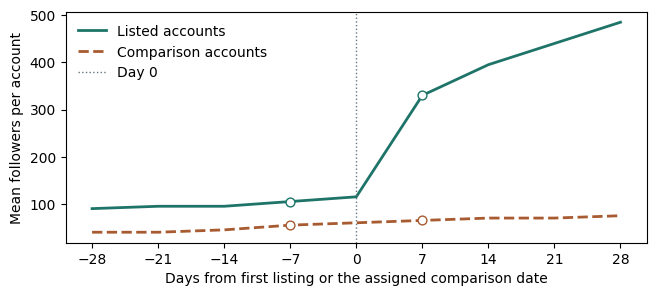

,Listed accounts,Comparison accounts
day,,
-7,105,55
7,330,65


In [7]:
# @title Compare Bluesky follower growth in two windows
import statsmodels.formula.api as smf

poll_choice = "Choose after reading" # @param ["Choose after reading", "A", "B", "C", "D"]
comparison_window = "One week before to one week after" # @param ["One week before to one week after", "Both dates before listing", "One week before to four weeks after"]
reveal_difference = True # @param {type:"boolean"}

check_vote(poll_choice, 'C', 'Correct choice: Dated first listings and follower counts before and after for comparable listed and unlisted accounts. Difference-in-differences needs a dated first listing and repeated follower counts for listed and comparable unlisted accounts.')

# Read from the member and control lines of Balduf et al. Figure 10(a), rounded to five followers.
trajectory = pd.read_csv(StringIO('day,member,control\n-28,90,40\n-21,95,40\n-14,95,45\n-7,105,55\n0,115,60\n7,330,65\n14,395,70\n21,440,70\n28,485,75\n')).set_index("day")
windows = {"One week before to one week after": (-7, 7), "Both dates before listing": (-21, -7),
           "One week before to four weeks after": (-7, 28)}
start, end = windows[comparison_window]
data_for_two_dates = trajectory.loc[[start, end]]
ax = trajectory.rename(columns={"member": "Listed accounts", "control": "Comparison accounts"}).plot(
    figsize=(7.5, 3), color=["#1e7468", "#a85b30"], style=["-", "--"], linewidth=2)
ax.axvline(0, color="#657680", linewidth=1, linestyle=":", label="Day 0")
for name, color in [("member", "#1e7468"), ("control", "#a85b30")]:
    ax.scatter([start, end], data_for_two_dates[name], edgecolor=color, facecolor="white", zorder=4, s=40)
ax.set(xlabel="Days from first listing or the assigned comparison date",
       ylabel="Mean followers per account", xticks=list(trajectory.index))
ax.legend(frameon=False, loc="upper left")
plt.show()
display(data_for_two_dates.rename(columns={"member": "Listed accounts", "control": "Comparison accounts"}))

if reveal_difference:
    changes = data_for_two_dates.loc[end] - data_for_two_dates.loc[start]
    cells = data_for_two_dates.reset_index().melt("day", var_name="group", value_name="followers")
    cells["member"] = cells["group"].eq("member").astype(int)
    cells["post"] = cells["day"].eq(end).astype(int)
    fit = smf.ols("followers ~ member * post", data=cells).fit()
    print(f"Listed accounts: {changes['member']:+.0f} · Comparison accounts: {changes['control']:+.0f}.")
    print(f"Difference in changes: about {fit.params['member:post']:+.0f} followers per account.")
    if end < 0:
        print("These two dates are both before day 0. Use this as a check on earlier trends.")
else:
    print("Calculate each change, then set reveal_difference to True and rerun.")

### Read changes in followers

Listed accounts gain about 225 followers per account and comparison accounts gain 10. The classroom difference in changes is about +215. Choosing days −21 and −7 gives about −5 for the same calculation entirely before listing. This earlier check helps assess whether the groups were already changing at different rates. Use account-level data to estimate how uncertain the result is or to redo the matching.

Choose **Both dates before listing** for the earlier check. Then compare one week before with four weeks after. The estimates describe different windows. The causal reading assumes the two groups would have gained similar numbers of followers without being listed, accounts did not change behavior in anticipation of listing, and listing one account did not change the comparison accounts’ outcomes. The authors observed different growth before the event for pack creators, so use pack members for this exercise.

**Connect to your project.** For your own exposure or policy, what dates, outcome, and comparison group could you verify? If any is missing, which dataset or research question would you change?

For a platform disclosure rule, identify which creators were covered, when it took effect, where unaffected accounts can be found, and whether both groups have follower histories.

## Comparative evaluation and revision

### Which model should a team use to screen environmental ads?

Compare three prediction algorithms on the same ads and explain which model fits a reviewer’s priorities.

Suppose you are screening oil and gas ads to find environmental messages for human review. A flag sends an ad to a reviewer. An ad is caught when the model flags it and a human reviewer labeled it Environment. A false flag sends a reviewer an ad without that label. More catches help researchers find relevant ads. False flags use up review time.

A benchmark uses the same data, task and scoring rules to compare methods. A leaderboard is a ranked table of results. A Pareto frontier highlights the choices for which no other model is at least as good on both measures and strictly better on one. For screening, it compares more catches and fewer false flags.

Automated machine learning (AutoML) fits and compares candidate models through one tool. AutoGluon is the Python package we use here. Logistic regression combines weighted inputs to estimate a probability. A random forest averages predictions from many decision trees, each of which makes a series of if–then splits. LightGBM builds a sequence of trees, each focusing on mistakes made by the earlier trees. That process is called gradient boosting.

For the second view, log loss measures how much probability the model gave to the actual label. A confident wrong prediction incurs a large loss. Lower is better. Prediction time, also called inference time, is how long the trained model takes to score the 193 ads together, shown in milliseconds (ms).

Recall is the share of the 78 reviewer-labeled Environment ads that the model caught. Precision is the share of flags that were correct. Precision is undefined if a model flags zero ads.

**Data.** Use the authors’ 193 training and 193 test videos. One row is one ad. All three models receive the same 648 numerical title weights and one scaled duration. AutoGluon keeps part of the training data for validation, a check during fitting. The 193 test ads remain separate and are used to score the fitted models.

- [TabArena paper · see Figure 5](https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf)
- [TabArena public leaderboard](https://tabarena.ai/)
- [Morio et al.’s advertising annotations · classroom data](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark)

| Symbol | Field or result | Meaning |
|---|---|---|
| X | 648 title word weights and standardized duration | The word weights and duration scale come from the training ads and are reused across all models. |
| Y, p̂, Ŷ | reviewer label, estimated probability, review flag | Y = 1 when a reviewer identified the Environment frame. Set Ŷ = 1 when p̂ is at least 0.50. |
| TP, FP | caught ads and false flags | TP counts flags with a human label of 1. FP counts flags with a human label of 0. |
| L, t | test log loss and prediction time | Compare lower probability error and fewer milliseconds to score the same 193 ads. |

**Vote before running.** Logistic regression catches 37 relevant ads and raises 37 false flags. Random forest catches 35 and raises 38 false flags. Which belongs on the frontier for catching more and raising fewer false flags?

- **A.** Logistic regression
- **B.** Random forest
- **C.** Both, because each catches some ads
- **D.** The answer requires knowing training time

Select `poll_choice` in the exercise cell and rerun it to check your reasoning. The class vote is in Ed Discussion.

### Equation and pseudocode

AutoGluon TabularPredictor.fit trains logistic regression, random forest, and LightGBM in one call. Its leaderboard scores the same test ads. The paretoset package identifies frontier models.

$$
A\ \mathrm{dominates}\ B\quad\text{if}\quad TP_A\ge TP_B,\quad FP_A\le FP_B,\quad\text{and at least one inequality is strict}
$$

A frontier model has no competitor that does as well on both measures and better on at least one. The time and log-loss view looks for smaller values on both axes.

$$
\mathrm{caught}=TP,\quad \mathrm{false\ flags}=FP,\quad \mathrm{recall}=\frac{TP}{TP+FN},\quad \mathrm{precision}=\frac{TP}{TP+FP}
$$

FN counts missed ads whose reviewer label is 1. When the number of flags is zero, precision has no denominator.

$$
L=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\ln \hat{p}_i+(1-y_i)\ln(1-\hat{p}_i)\right]
$$

Log loss uses the probability assigned to each actual label. If an ad’s true label is 1, predicting 0.90 incurs a smaller loss than predicting 0.10.

1. Learn the title vocabulary, word weights and duration scale from the 193 training ads. Apply the same transformations to the 193 test ads.
2. Call AutoGluon fit once with three model types. Score them on the same test rows with leaderboard.
3. Apply the same 0.50 cutoff for all three models and count correct and false flags.
4. Identify the best trade-offs for each pair of measures and decide which model you would use for screening.

[AutoGluon · fit all three model types](https://auto.gluon.ai/1.5/api/autogluon.tabular.TabularPredictor.fit.html) · [AutoGluon · score trained models](https://auto.gluon.ai/1.5/api/autogluon.tabular.TabularPredictor.leaderboard.html) · [AutoGluon · model types](https://auto.gluon.ai/1.5/api/autogluon.tabular.models.html) · [paretoset · find models with no better alternative on both measures](https://pypi.org/project/paretoset/)

### Train the three models once

[TabArena](https://tabarena.ai/) compares many models across shared tasks. [Figure 5 of the paper](https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf#page=8) compares a summary of predictive performance with prediction time. Here we use one dataset and place the three trained models on two plots that answer different practical questions.

AutoGluon uses part of the training split for validation. The test split is used to compare the trained models. The two ranking controls only display those computed scores, so changing a view takes no retraining. A run on another computer will record different prediction times.

In [8]:
# @title Fit AutoGluon and score all three models on the same test ads
from tempfile import TemporaryDirectory

from autogluon.tabular import TabularPredictor
from paretoset import paretoset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

train, test = ads("train"), ads("test")
words = TfidfVectorizer().fit(train["video_title"])
duration = StandardScaler().fit(train[["video_length_seconds"]])

def model_table(rows):
    x = pd.DataFrame(words.transform(rows["video_title"]).toarray(),
                     columns=["word_" + word for word in words.get_feature_names_out()])
    x["duration"] = duration.transform(rows[["video_length_seconds"]]).ravel()
    x["Environment"] = environment(rows).to_numpy()
    return x

train_table, test_table = model_table(train), model_table(test)
model_names = {"LinearModel": "Logistic regression",
               "RandomForest": "Random forest", "LightGBM": "LightGBM"}

# AutoGluon fits one configuration per algorithm and uses training-only validation.
with TemporaryDirectory() as folder:
    predictor = TabularPredictor(label="Environment", problem_type="binary", positive_class=1,
                                 eval_metric="log_loss", path=folder, verbosity=0)
    predictor.fit(train_table,
                  hyperparameters={"LR": {}, "RF": {"random_state": 7}, "GBM": {"seed": 7}},
                  holdout_frac=0.2, fit_weighted_ensemble=False,
                  calibrate_decision_threshold=False, num_cpus=2, num_gpus=0)
    arena = predictor.leaderboard(test_table)[["model", "score_test", "pred_time_test"]].copy()
    actual = test_table["Environment"].eq(1)
    inputs = test_table.drop(columns="Environment")
    caught, false_flags = [], []
    for model in arena["model"]:
        flag = predictor.predict_proba(inputs, model=model, as_multiclass=False).ge(0.50)
        caught.append(int((flag & actual).sum()))
        false_flags.append(int((flag & ~actual).sum()))

arena["model"] = arena["model"].map(model_names)
arena["log_loss"] = -arena.pop("score_test")  # AutoGluon reports negative log loss.
arena["batch_ms"] = 1000 * arena.pop("pred_time_test")
arena["caught"], arena["false_flags"] = caught, false_flags
arena["recall"] = arena["caught"] / actual.sum()
flags = arena["caught"] + arena["false_flags"]
arena["precision"] = arena["caught"] / flags.where(flags > 0)  # Undefined with zero flags.
arena["frontier"] = paretoset(arena[["log_loss", "batch_ms"]], sense=["min", "min"], distinct=False)
arena["screen_frontier"] = paretoset(arena[["false_flags", "caught"]], sense=["min", "max"], distinct=False)
arena = arena.sort_values(["log_loss", "batch_ms"]).reset_index(drop=True)

print(f"Held-out ads: {len(test_table)} | Environment labels: {test_table.Environment.sum()}")
columns = ["model", "caught", "false_flags", "recall", "precision", "log_loss", "batch_ms",
           "screen_frontier", "frontier"]
print(arena[columns].round(3).to_string(index=False, na_rep="—"))

Held-out ads: 193 | Environment labels: 78
              model  caught  false_flags  recall  precision  log_loss  batch_ms  screen_frontier  frontier
           LightGBM       0            0   0.000          —     0.675     2.039             True      True
      Random forest      35           38   0.449      0.479     0.691    51.757            False     False
Logistic regression      37           37   0.474      0.500     0.881    31.974             True     False


Choose A, B, C or D to check your reasoning.
193 test ads. Human reviewers labeled 78 Environment.


,Model,Caught ↑,False flags ↓,Recall ↑,Precision ↑,Pareto frontier
Rank,,,,,,
1,Logistic regression,37,37,47.4%,50.0%,On frontier
2,Random forest,35,38,44.9%,47.9%,Off frontier
3,LightGBM,0,0,0.0%,Undefined,On frontier


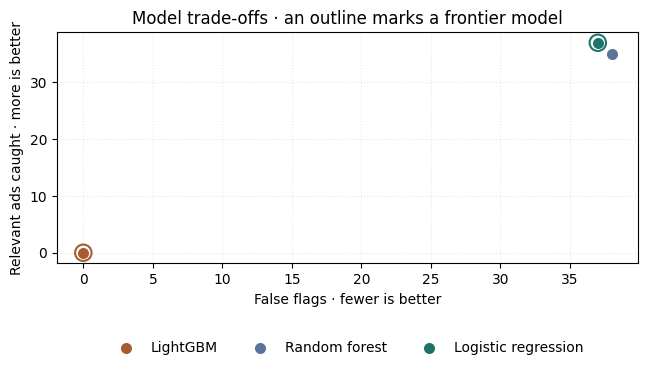

In [9]:
# @title Change the comparison and sort the leaderboard
poll_choice = "Choose after reading" # @param ["Choose after reading", "A", "B", "C", "D"]
comparison = "Screen for review" # @param ["Screen for review", "Compare probability and speed"]
screen_sort = "Most ads caught" # @param ["Most ads caught", "Fewest false flags"]
probability_sort = "Lowest log loss" # @param ["Lowest log loss", "Shortest prediction time"]

check_vote(poll_choice, 'A', 'Correct choice: Logistic regression. Logistic regression catches two more relevant ads and sends one fewer false flag for review. It does better than random forest on both screening measures.')

if comparison == "Screen for review":
    x, y, frontier = "false_flags", "caught", "screen_frontier"
    x_label, y_label = "False flags · fewer is better", "Relevant ads caught · more is better"
    order = {"Most ads caught": ("caught", False), "Fewest false flags": ("false_flags", True)}[screen_sort]
    columns = {"model": "Model", "caught": "Caught ↑", "false_flags": "False flags ↓",
               "recall": "Recall ↑", "precision": "Precision ↑", frontier: "Pareto frontier"}
else:
    x, y, frontier = "batch_ms", "log_loss", "frontier"
    x_label, y_label = "Time to score 193 ads (ms) · lower is better", "Test log loss · lower is better"
    order = {"Lowest log loss": ("log_loss", True), "Shortest prediction time": ("batch_ms", True)}[probability_sort]
    columns = {"model": "Model", "log_loss": "Log loss ↓", "batch_ms": "Time (ms) ↓",
               "caught": "Caught at 0.50", frontier: "Pareto frontier"}

ordered = arena.sort_values(order[0], ascending=order[1], kind="stable")
table = ordered[list(columns)].rename(columns=columns).reset_index(drop=True)
table.index = table.index + 1
table.index.name = "Rank"
for name in ["Recall ↑", "Precision ↑"]:
    if name in table:
        table[name] = table[name].map(lambda v: f"{v:.1%}" if pd.notna(v) else "Undefined")
table["Pareto frontier"] = table["Pareto frontier"].map({True: "On frontier", False: "Off frontier"})
print(f"{len(test)} test ads. Human reviewers labeled {environment(test).sum()} Environment.")
display(table.round(3))

colors = {"Logistic regression": "#1e7468", "Random forest": "#577499", "LightGBM": "#a85b30"}
fig, ax = plt.subplots(figsize=(7.5, 3))
for row in arena.to_dict(orient="records"):
    color = colors[row["model"]]
    ax.scatter(row[x], row[y], color=color, s=48, zorder=3, label=row["model"])
    if row[frontier]:
        ax.scatter(row[x], row[y], s=140, facecolors="none", edgecolors=color, linewidths=1.5, zorder=4)
ax.set(xlabel=x_label, ylabel=y_label, title="Model trade-offs · an outline marks a frontier model")
ax.grid(linestyle=":", alpha=0.30)
ax.legend(bbox_to_anchor=(0.5, -0.28), loc="upper center", ncol=3, frameon=False)
plt.show()

### Decide what counts as better

On this class run, logistic regression catches 37 of the 78 labeled Environment ads with 37 false flags. Random forest catches 35 with 38 false flags. LightGBM gives the lowest log loss and flags zero ads at 0.50 in this run. Timing is from one run and varies by computer. The three models use a single test split, so the scores describe this comparison. The prediction reply’s standalone logistic regression uses a different training procedure. Its score can differ from AutoGluon’s logistic regression.

For this screening task, zero false flags can come from flagging nothing. Start by specifying a minimum number of ads you need to catch. Then compare the viable models and explain how much human review each requires. A later study could compare better text or visual inputs on a fresh test set. Rank by catches, then by false flags. Next switch to **Compare probability and speed**. Explain which ranking fits the screening decision and name a result that could change your choice.

**Connect to your project.** Which two measures would your project use to compare models, which direction is better for each, and how would you assess them on the same test cases?

For a flood-alert model, compare how many real events are caught and how many residents receive false alarms. Define separately how quickly a prediction must reach people.

## Optimization · TBD

See the two-page methods cheat sheet for the overview.

## Team project design

Choose a question and one main method. Identify what one row represents, define the variables your method needs, link the dataset and its associated paper, and name the comparison you will use. Give a teammate one specific assumption or measure to challenge. Use their feedback to revise your design and assign one next output to each person.

Use the inline example to draft a plan. Bring it into your team’s one-page design in [draw.io](https://app.diagrams.net/) or [Excalidraw](https://excalidraw.com/). Post one team reply in Ed with the question, team, data and paper links, your editable design or export, and the division of work.

In [10]:
# @title Revise the sample plan for your own project
question = "Which oil and gas ads with an environmental message does a title-and-duration screen miss?" # @param {type:"string"}
row_and_data = "One YouTube ad. Use Morio et al.'s test split and collect independently checked transcript cues for a new batch." # @param {type:"string"}
method_and_variables = "Prediction. Inputs X are title words and duration. Target Y is the reviewer's Environment label." # @param {type:"string"}
comparison = "Compare title-and-duration logistic regression with a model that also uses coded transcript cues. Report catches and false flags on one fresh batch." # @param {type:"string"}
peer_challenge = "Does the new measure help on ads where the environmental message appears only in the visuals?" # @param {type:"string"}
revision = "Mark whether each relevant message comes from spoken words, images, or both, then test the models on an untouched set." # @param {type:"string"}
next_output = "A teammate brings a list of source links and ten double-checked coding examples to the next meeting." # @param {type:"string"}

fields = {"Research question": question, "One row and data source": row_and_data, "Method and variables": method_and_variables,
          "Fair comparison": comparison, "Peer challenge": peer_challenge, "Revision": revision, "Owner and next output": next_output}
for label, answer in fields.items():
    print(f"{label}\n{answer}\n")

Research question
Which oil and gas ads with an environmental message does a title-and-duration screen miss?

One row and data source
One YouTube ad. Use Morio et al.'s test split and collect independently checked transcript cues for a new batch.

Method and variables
Prediction. Inputs X are title words and duration. Target Y is the reviewer's Environment label.

Fair comparison
Compare title-and-duration logistic regression with a model that also uses coded transcript cues. Report catches and false flags on one fresh batch.

Peer challenge
Does the new measure help on ads where the environmental message appears only in the visuals?

Revision
Mark whether each relevant message comes from spoken words, images, or both, then test the models on an untouched set.

Owner and next output
A teammate brings a list of source links and ten double-checked coding examples to the next meeting.



## References

### Data and measurement

Read the authors’ label guide to decide what the Environment frame measures.

Morio, G., Rowlands, H., Stammbach, D., Manning, C.D., Henderson, P. (2025). A Multimodal Benchmark for Framing of Oil & Gas Advertising and Potential Greenwashing Detection. Advances in Neural Information Processing Systems 38, 98266-98292. <https://doi.org/10.52202/085713-2956>

Recent review and further reading
Joung, E.G. (2026). Computational Public Opinion Measurement: A Systematic Review of Methods and Methodological Limitations. Social Science Computer Review, 08944393261457540. <https://doi.org/10.1177/08944393261457540>

### Explanation

Sweeney and colleagues grouped climate discourse to study patterns in public conversation. Our class groups ads using four labels.

Sweeney, L., Mehrotra, R., Saintraint, F., Brennan, R.A., Suiter, J. (2026). Reading the climate room through unsupervised analysis of unfiltered climate perspectives. Scientific Reports, 16(1), 14828. <https://doi.org/10.1038/s41598-026-44553-x>

Recent review and further reading
M, Y., S, S. (2026). A comprehensive survey on clustering algorithms: concepts, taxonomy with nature-inspired meta-heuristic approaches and performance metrics. Humanities and Social Sciences Communications. <https://doi.org/10.1057/s41599-026-08506-z>

### Prediction

Lu and colleagues used company disclosures to study business opportunities for climate solutions. They classified documents based on the language companies used.

Lu, S., Serafeim, G., Xu, S., Awada, M. (2025). Tracking business opportunities for climate solutions using AI in regulated accounting reports. Nature Communications, 16(1), 9769. <https://doi.org/10.1038/s41467-025-64723-1>

Recent review and further reading
Joseph, P.K., Odumuyiwa, V. (2026). From word to sentence embedding and beyond: Bridging the gap in text representation survey. Natural Language Processing Journal, 15, 100214. <https://doi.org/10.1016/j.nlp.2026.100214>

Allam, H., Makubvure, L., Gyamfi, B., Graham, K. N., & Akinwolere, K. (2025). Text Classification: How Machine Learning Is Revolutionizing Text Categorization. Information, 16(2), 130. <https://doi.org/10.3390/info16020130>

### Causal inference

Balduf and colleagues used difference-in-differences to study social media visibility. For a related climate-ad question, Sankaranarayanan and colleagues studied Facebook ad delivery using a different design.

Balduf, L., Sokoto, S., Baronchelli, A., Castro, I., Król, M., Tyson, G., Pavlou, G., Scheuermann, B., & Ascigil, O. (2025). Bootstrapping Social Networks: Lessons from Bluesky Starter Packs. Proceedings of the International AAAI Conference on Web and Social Media, 19(1), 178–192. <https://doi.org/10.1609/icwsm.v19i1.35810>

Sankaranarayanan, A., Sapiezynski, P., O’Reilly, U. (2025). Facebook algorithm’s active role in climate advertisement delivery. Nature Climate Change, 15(7), 719-724. <https://doi.org/10.1038/s41558-025-02326-w>

Recent review and further reading
Baker, A., Callaway, B., Cunningham, S., Goodman-Bacon, A., & Sant’Anna, P. H. C. (2026). Difference-in-Differences Designs: A Practitioner’s Guide. Journal of Economic Literature, 64(2), 498–557. <https://doi.org/10.1257/jel.20251650>

### Comparative evaluation and revision

TabArena compares many models on common tasks and displays a public leaderboard. Figure 5 plots a summary measure of prediction quality against prediction time. Our classroom version compares the three models on a single public ad dataset.

Erickson, N., Purucker, L., Tschalzev, A., Holzmüller, D., Mutalik Desai, P., Salinas, D., & Hutter, F. (2025). TabArena: A Living Benchmark for Machine Learning on Tabular Data. 39th Annual Conference on Neural Information Processing Systems (NeurIPS), Datasets and Benchmarks Track. <https://papers.neurips.cc/paper_files/paper/2025/file/1697e3fb412da11dc9488249f9e7bbc9-Paper-Datasets_and_Benchmarks_Track.pdf>

Recent review and further reading
Van Calster, B., Collins, G.S., Vickers, A.J., Wynants, L., Kerr, K.F., Barreñada, L., Varoquaux, G., Singh, K., Moons, K.G., Hernandez-Boussard, T., Timmerman, D., McLernon, D.J., van Smeden, M., Steyerberg, E.W. (2025). Evaluation of performance measures in predictive artificial intelligence models to support medical decisions: overview and guidance. The Lancet Digital Health, 7(12), 100916. <https://doi.org/10.1016/j.landig.2025.100916>

### How we learn in this lab

Howard, J. L., Slemp, G. R., & Wang, X. (2025). Need support and need thwarting: A meta-analysis of autonomy, competence, and relatedness supportive and thwarting behaviors in student populations. Personality and Social Psychology Bulletin, 51(9), 1552–1573. <https://doi.org/10.1177/01461672231225364>

Akveld, M., Docherty, P., Kinnear, G., & Sangwin, C. J. (2026). Question design for classroom voting in undergraduate mathematics: A systematic review of the literature. International Journal of Research in Undergraduate Mathematics Education, 12(2), 295–324. <https://doi.org/10.1007/s40753-025-00278-2>

Hornstein, J., Keller, M. V., Greisel, M., Dresel, M., & Kollar, I. (2025). Enhancing the peer-feedback process through instructional support: A meta-analysis. Educational Psychology Review, 37(2), Article 42. <https://doi.org/10.1007/s10648-025-10017-3>

### Package and workflow references

- [Colab form controls](https://colab.research.google.com/notebooks/forms.ipynb)
- [Hugging Face benchmark at the version used here](https://huggingface.co/datasets/climate-nlp/multimodal-oil-gas-benchmark/tree/98c8b5266ae6247f71957f7b8b4ad7919cc7262e)
- [Week 4 Causal ML for the longer causal walkthrough](https://github.com/sunshineluyao/ml4ss/blob/main/modules/04-causal-inference/week04_causal_ml.ipynb)
- [Code license](https://github.com/sunshineluyao/ml4ss/blob/main/LICENSE). Data and original publications retain their own terms.